# mkNeVmap — [NeV] in M82 with MIRI MRS

Notebook version of `mk_nev_map.py`, the Python port of `mkNeVmap.m` (matlab_slice_10222026).
Each Matlab `%%` cell is a section here:

1. [NeV] 14.32 µm peak map with the seven sources and Fenech et al. SNRs
2. X-ray image with the MRS footprints and the ULX X-1 boxes
3. Differential (aperture − annulus) spectra and multi-channel figures for sources 3, 1, 2, 4
4. Gaussian fits to broadened lines in source 3
5. ULX X-1 ch4 spectrum and [OIV] luminosity

Run the notebook from `python_slice_10222026/`.  Inputs are read from `../JWST`; outputs go to
`OUT_DIR` (default `mk_nev_map_output/`, so the Matlab products in `JWST/` are not overwritten).

In [1]:
import os
import sys
sys.path.insert(0, os.path.abspath('.'))   # slice_lib.py lives next to this notebook

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Annulus, Circle
from matplotlib.ticker import NullFormatter

from slice_lib import (read_fits, sex2dec, make_map, diff_spec, cat_peaks,
                       gaussfit)
# slice_lib selects the non-interactive Agg backend on import, so switch to inline after it
%matplotlib inline

## Configuration
Paths, source positions (sorted in increasing RA), aperture radii, line lists and the per-source figure settings.

In [2]:
# ---------------------------------------------------------------------------
# Configuration – adjust paths as needed
# ---------------------------------------------------------------------------
DATA_DIR = os.path.abspath(os.path.join('..', 'JWST'))
OUT_DIR = os.path.abspath('mk_nev_map_output')   # Matlab wrote into JWST/ itself
os.makedirs(OUT_DIR, exist_ok=True)

CUBE = os.path.join(DATA_DIR, 'M82_sky_v2_ch?-shortmediumlong_s3d.fits')
XRAY = os.path.join(DATA_DIR, 'broad_norm.fits')
FENECH = os.path.join(DATA_DIR, 'Fenech.reg')

PKO = [('09:55:52.74', '69:40:45.89'), ('09:55:51.276', '69:40:44.09'),
       ('09:55:54.461', '69:40:51.448'), ('09:55:54.55', '69:40:49.1'),
       ('09:55:51.54', '69:40:45.87'), ('09:55:52.95', '69:40:47.51'),
       ('09:55:53.91', '69:40:48.48')]
ARROW0 = np.array([[-2, -2], [-1.5, -3.5], [3, -3], [1, -1.5], [-2, 4], [2, 5], [1, -2]])

# Fixing the order so it's in increasing RA order
_ix = np.argsort(sex2dec([p[0] for p in PKO]), kind='stable')
PKA = [PKO[i] for i in _ix]
ARROW = ARROW0[_ix]

# Reference position: Lester et al 1990 2um peak (J2000)
REFRA = sex2dec('09:55:52.3') * 15
REFDE = sex2dec('69:40:46.1')
DIST = 3.6e6   # pc

# Radii (arcsec) of central aperture, inner and outer annulus, per channel
R = np.array([[0.2, 0.2, 0.3, 0.4],
              [0.6, 0.6, 0.7, 0.85],
              [0.4, 0.4, 0.5, 0.6]])

LINELIST = np.array([5.057, 5.130, 5.342, 5.513, 5.611, 5.910, 6.109, 6.113, 6.294,
                     6.638, 6.912, 6.988, 7.355, 7.462, 7.505, 7.5104, 7.6527, 8.0258,
                     8.9921, 9.6659, 10.5110, 10.6833, 9.3948, 11.006, 8.763, 7.7836,
                     12.288, 12.382, 12.824, 14.324, 14.332, 14.378, 15.561, 17.048,
                     17.900, 17.950, 18.7277, 22.94, 24.3364, 25.907, 26.0092])
# source 4 and ULX: adds H7beta, H7alpha and [ArIII] 21.8
LINELIST4 = np.array([5.057, 5.130, 5.342, 5.513, 5.611, 5.910, 6.109, 6.113, 6.294,
                      6.638, 6.912, 6.988, 7.355, 7.462, 7.505, 7.5104, 7.6527, 8.0258,
                      8.9921, 9.6659, 10.5110, 10.6833, 9.3948, 11.006, 8.763, 7.7836,
                      11.3171, 12.288, 12.382, 12.824, 14.324, 14.332, 14.378, 15.561,
                      17.048, 17.900, 17.950, 18.7277, 19.069, 21.840, 22.94, 24.3364,
                      25.907, 26.0092])

# Rest wavelengths and labels for the multi-channel figures
LINES1 = [5.0528, 5.1283, 5.3398, 5.5108, 5.6091, 5.9075, 6.1079, 6.6356, 6.9088,
          6.9848, 7.3518, 7.4596, 7.5021]
LAB1 = ['S(8)', r'Hu$\delta$', '[FeII]', 'S(7)', '[MgV]', r'Hu$\gamma$', 'S(6)',
        '[NiII]', 'S(5)', '[ArII]', '[NiIII]', r'Pf$\alpha$', r'Hu$\beta$']
LINES2 = [7.6515, 8.0251, 8.7597, 8.9914, 9.6640, 10.510, 10.6817, 11.0020]
LAB2 = ['[NeVI]', 'S(4)', r'H7$\gamma$', '[ArIII]', 'S(3)', '[SIV]', '[NiII]', '[NiIII]']
LINES3 = [12.2788, 12.3715, 12.8139, 14.3207, 14.3661, 15.5561, 17.0352, 17.8850, 17.9359]
LAB3 = ['S(2)', r'Hu$\alpha$', '[NeII]', '[NeV]', '[ClII]', '[NeIII]', 'S(1)',
        '[PIII]', '[FeII]']
LINES4 = [17.8858, 17.9359, 18.7123, 22.9283, 24.3178, 25.8872, 25.9878]
LAB4 = ['[PIII]', '[FeII]', '[SIII]', '[FeIII]', '[NeV]', '[OIV]', 'FeII']

# Per-source settings of the differential spectra and multi-channel figures.
# panels: (lines, labels, dir, ylim, spoff, dfoff, vfraclab) per channel
SOURCES = {
    3: dict(vlsr=230, fac=1.0004, linelist=LINELIST, chans=[1, 2, 3, 4], panels=[
        (LINES1, LAB1, [1, 0, 0, 1, 0, 0, -1, 1, -1, 1, 0, 0, 0], [4000, 5e4], 5000, 4800, 0.4),
        (LINES2, LAB2, [1, 1, 0, 1, 1, 1, 0, 0], [6000, 20000], 5000, 6400, 0.4),
        (LINES3, LAB3, [-1, 0, 1, -1, 0, 1, 1, 0, -1], [8e3, 2e5], 5000, 0.95e4, 0.5),
        (LINES4, LAB4, [0, 1, 0, 0, 1, 1, 0], [1.8e4, 1e5], 5000, 2e4, 0.4)]),
    1: dict(vlsr=110, fac=1.0, linelist=LINELIST, chans=[1, 2, 3, 4], panels=[
        (LINES1, LAB1, [0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0], [4000, 2e5], 5000, 5500, 0.29),
        (LINES2, LAB2, [1, 0, 0, 0, 0, 0, 0, 0], [6000, 40000], 5000, 7400, 0.4),
        (LINES3, LAB3, [0, 0, 0, -1, 0, 0, 0, 0, 0], [1.2e4, 7e5], 5000, 1.6e4, 0.4),
        (LINES4, LAB4, [0, 0, 0, 0, 1, 0, 0], [3.5e4, 3e5], 5000, 3.9e4, 0.4)],
        # insets: (axes position, x range, y range) of the differential spectrum
        insets=[([0.303, 0.13, 0.06, 0.14], [5.58, 5.64], [0, 1000]),
                ([0.15, 0.36, 0.06, 0.14], [7.58, 7.72], [600, 2300]),
                ([0.34, 0.58, 0.06, 0.14], [14.2, 14.45], [1000, 2000]),
                ([0.55, 0.83, 0.06, 0.14], [24.15, 24.5], [6000, 7200])]),
    2: dict(vlsr=150, fac=1.0, linelist=LINELIST, chans=[1, 2, 3, 4], panels=[
        (LINES1, LAB1, [0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0], [4400, 3e4], 5000, 5500, 0.4),
        (LINES2, LAB2, [0, 0, 0, 1, 0, 1, 0, 0], [5000, 20000], 5000, 6000, 0.4),
        (LINES3, LAB3, [0, 0, 0, -1, 0, 0, 0, 0, 0], [0.7e4, 1e5], 5000, 1e4, 0.4),
        (LINES4, LAB4, [0, 0, 0, 0, 0, 1, 0], [1e4, 1e5], 5000, 2e4, 0.4)]),
    # Matlab computes only ch4 for source 4 (for ch=4:4)
    4: dict(vlsr=250, fac=1.0004, linelist=LINELIST4, chans=[4], panels=[
        (LINES1, LAB1, [0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, -1, 1], [5000, 0.5e5], 5000, 5500, 0.29),
        (LINES2 + [11.3087], LAB2 + [r'H7$\beta$'], [0, 0, 0, 0, 0, 0, 0, 0, 1],
         [0.7e4, 3e4], 5000, 8000, 0.4),
        (LINES3, LAB3, [0, 1, 0, -1, 0, 0, 0, -1, 0], [1.2e4, 7e5], 5000, 1.6e4, 0.4),
        ([17.8858, 17.9359, 18.7123, 19.0625, 21.8314, 22.9283, 24.3178, 25.8872, 25.9878],
         ['[PIII]', '[FeII]', '[SIII]', r'H7$\alpha$', '[ArIII]', '[FeIII]', '[NeV]',
          '[OIV]', 'FeII'], [1, 0, 1, 1, 1, 0, 0, 1, 0], [3.5e4, 3e5], 5000, 3.9e4, 0.4)]),
}

### Helpers

In [3]:
def _mround(v):
    """Matlab round (half away from zero) for positive values, as an int."""
    return int(np.floor(v + 0.5))


def _offsets(r):
    """RA/Dec offset axes (arcsec) from the reference position, as in mkNeVmap."""
    nx, ny = int(r['numpt'][0]), int(r['numpt'][1])
    x = (r['wcs1'] - REFRA) * 3600 * np.cos(np.radians(REFDE))
    x = x[_mround(nx / 2) - 1, :]
    y = (r['wcs2'] - REFDE) * 3600
    y = y[:, _mround(ny / 2) - 1]
    return x, y


def _xy(ra, dec):
    """Offsets (arcsec) of a sexagesimal position from the reference position."""
    return ((sex2dec(ra) * 15 - REFRA) * np.cos(np.radians(REFDE)) * 3600,
            (sex2dec(dec) - REFDE) * 3600)


def _out(name):
    return os.path.join(OUT_DIR, name)

## [NeV] map
`make_map` on the ch3 cube (writes `NeV14.3-M82v2.fits`, 14 planes); peak intensity with peak/rms contours at 6, 10, 15.  Saves `NeV-peakSNR.png`.

In [4]:
def nev_map_figure():
    """[NeV] peak intensity map with SNR contours and sources.  NeV-peakSNR.png"""
    cube = CUBE.replace('?', '3')
    maps = make_map(cube, _out('NeV14.3-M82v2'), [14.27, 14.317, 14.3435, 14.355], 3,
                    [14.3185, 14.3440], 'reject4')
    cc = read_fits(cube, 'head xten1')
    x, y = _offsets(cc)
    rah = REFRA / 15
    print(f'Offsets from RA={int(rah):02d}:{int(rah*60 % 60):02d}:{rah*3600 % 60:06.3f}, '
          f'DE={int(REFDE):+02d}:{int(REFDE*60 % 60):02d}:{REFDE*3600 % 60:06.3f}')
    maps['peak'][56, 66] = np.nan
    kk = maps['peak'].copy()
    kk[kk == 0] = np.nan

    fig = plt.figure(figsize=(10, 5.2))
    ax = fig.add_axes([0.03, 0.09, 0.9, 0.9])
    ax.set_facecolor([0.4] * 3)
    im = ax.pcolormesh(x, y, kk.T, shading='nearest', vmin=-50, vmax=2000)
    ax.contour(x, y, (maps['peak'] / maps['rms']).T, [6, 10, 15], colors='w')
    cb = fig.colorbar(im, ax=ax)
    cb.set_label('Peak Intensity (MJy/sr)', fontsize=18)
    ax.set_xlabel('R.A. Offset (arcsec)', fontsize=16)
    ax.set_ylabel('Dec. Offset (arcsec)', fontsize=16)
    ax.tick_params(labelsize=16, width=2)

    for i, (ra, dec) in enumerate(PKA):
        xx, yy = _xy(ra, dec)
        axx, ayy = ARROW[i]
        ax.plot(xx + np.array([0, axx]), yy + np.array([0, ayy]), '-w')
        ax.text(xx + axx + np.sign(axx) * 0.4, yy + ayy + np.sign(ayy) * 0.4, str(i + 1),
                color='w', ha='center', va='center', fontsize=20)

    if os.path.exists(FENECH):
        import re
        with open(FENECH) as fp:
            regs = re.findall(r'circle\(([^,]+),([^,]+),', fp.read())
        for i, (ra, dec) in enumerate(regs):
            xx, yy = _xy(ra.strip(), dec.strip())
            if abs(xx) < 16 and abs(yy) < 9:
                ax.text(xx, yy, str(i + 1), color='m', ha='center', va='center', fontsize=12)
    else:
        print(f'{FENECH} not found: skipping Fenech SNR labels')

    ax.set_xlim(16, -16)
    ax.set_ylim(-9, 9)
    ax.set_aspect('equal')
    for sp in ax.spines.values():
        sp.set_linewidth(2)

    ax.plot(*_xy('09:55:52.3', '69:40:46.1'), '+w', markersize=16, mew=1.5)
    L = 200 / DIST * 180 * 3600 / np.pi
    ax.plot([15, 15 - L], [-8, -8], '-w', linewidth=3)
    ax.text(15 - L / 2, -7.9, '200 pc', ha='center', va='bottom', color='w', fontsize=16)
    # aperture and annulus used for the ch3 differential spectra
    ax.add_patch(Circle((-12.5, 6.5), R[0, 2], color='w', ec='none'))
    ax.add_patch(Annulus((-12.5, 6.5), R[1, 2], R[1, 2] - R[2, 2], color='w', ec='none'))
    bm = 1.2 * 14.3e-6 / 6.5 * 180 * 3600 / np.pi / 2
    ax.add_patch(Circle((14.5, -6), bm, color='w', ec='none'))
    ax.text(14, -6, 'Resolution', color='w', va='center', fontsize=16)
    fig.savefig(_out('NeV-peakSNR.png'), dpi=100, facecolor='w', bbox_inches='tight')
    plt.show()
    return maps

/janskyraid/bolatto/claude/slice/python_slice_10222026/slice_lib.py:295: RuntimeWarning: divide by zero encountered in divide
  theta = np.arctan(180.0 / (np.pi * np.sqrt(dx**2 + dy**2)))


/janskyraid/bolatto/claude/slice/python_slice_10222026/slice_lib.py:1021: RuntimeWarning: overflow encountered in scalar power
  + q['K'][i]**2 * ednu**2))


Offsets from RA=09:55:52.300, DE=+69:40:46.100


/janskyraid/bolatto/claude/slice/python_slice_10222026/slice_lib.py:1374: RuntimeWarning: overflow encountered in cast
  cube = np.stack(planes, axis=2).astype(np.float32)
/tmp/ipykernel_3928938/1685332965.py:19: RuntimeWarning: invalid value encountered in divide
  ax.contour(x, y, (maps['peak'] / maps['rms']).T, [6, 10, 15], colors='w')


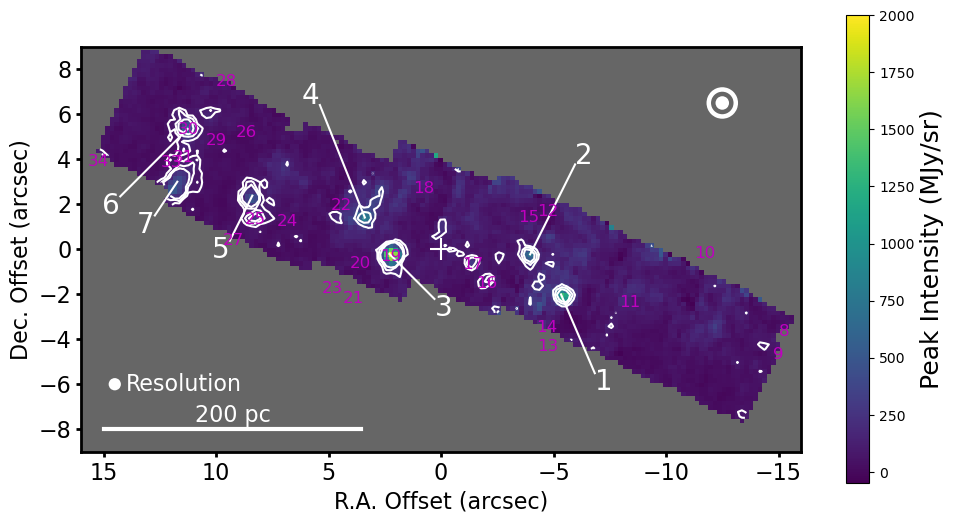

In [5]:
mapNeV = nev_map_figure()

## X-ray image
Saves `Xray-image.png`.  Skipped if `JWST/broad_norm.fits` is missing.

In [6]:
def xray_figure():
    """X-ray image with ch3/ch4 footprints, sources and ULX boxes.  Xray-image.png"""
    if not os.path.exists(XRAY):
        print(f'{XRAY} not found: skipping X-ray figure')
        return
    xray = read_fits(XRAY, 'wcs')
    nx, ny = int(xray['numpt'][0]), int(xray['numpt'][1])
    xxr = (xray['wcs1'][:, _mround(nx / 2) - 1] - REFRA) * 3600 * np.cos(np.radians(REFDE))
    yxr = (xray['wcs2'][_mround(ny / 2) - 1, :] - REFDE) * 3600
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(np.sqrt(xray['data']).T, origin='lower', vmin=0, vmax=60,
              extent=[xxr[0], xxr[-1], yxr[0], yxr[-1]])
    for ch, col in ((3, 'r'), (4, 'm')):
        ifu = read_fits(CUBE.replace('?', str(ch)), 'xten1')
        x, y = _offsets(ifu)
        i1 = np.all(np.isfinite(ifu['data'][:, :, :-15]), axis=2).astype(float)
        ax.contour(x, y - 0.5, i1.T, [0.5], colors=col, linewidths=2)
    th = np.radians(np.arange(0, 361, 10))
    for ra, dec in PKA:
        xx, yy = _xy(ra, dec)
        ax.plot(xx + np.cos(th), yy + np.sin(th), 'w-', linewidth=2)
    ax.plot(0, 0, '+w', markersize=20)
    sq = np.array([[-1, -1], [1, -1], [1, 1], [-1, 1], [-1, -1]]).T
    a = np.radians(25)
    sqr = np.array([[np.cos(a), np.sin(a)], [-np.sin(a), np.cos(a)]]) @ sq
    xu, yu = _xy('09:55:50.11', '69:40:46.76')
    ax.plot(xu + 2.75 * sqr[0], yu + 2.75 * sqr[1], 'w-', linewidth=2)
    ax.plot(xu + 1.5 * sqr[0], yu + 1.5 * sqr[1], '-', linewidth=2, color=[1, 0.647, 0])
    ax.set_xlim(20, -20)
    ax.set_ylim(-20, 20)
    ax.set_aspect('equal')
    ax.tick_params(labelsize=16)
    ax.set_xlabel('R.A. Offset (")', fontsize=16)
    ax.set_ylabel('Dec. Offset (")', fontsize=16)
    fig.savefig(_out('Xray-image.png'), dpi=100, bbox_inches='tight')
    plt.show()

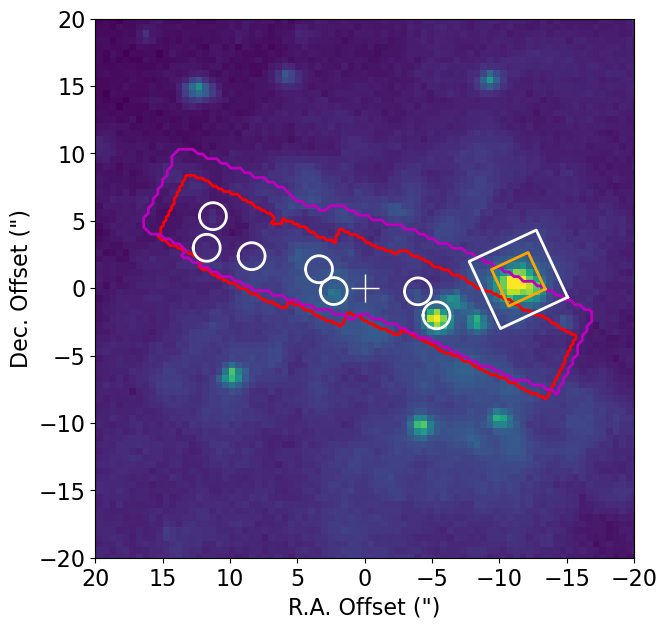

In [7]:
xray_figure()

## Differential spectra and multi-channel figures
`diff_spec` extracts the central aperture and two circular apertures (radii R1, R2) and forms center − annulus.  Figures `diffSpecSrc{n}.png`.

In [8]:
def diff_spectra(src):
    """Differential spectra of a source in its channels; returns {ch: dss}."""
    cfg = SOURCES[src]
    return {ch: diff_spec(CUBE, PKA, ch, src, R, cfg['linelist'] * cfg['fac'],
                          cfg['vlsr'], outdir=OUT_DIR)
            for ch in cfg['chans']}


def plot_spec(fig, nplt, sp, lines, linelab, dirs, ylim, spoff, dfoff, vfraclab):
    """Port of the plotSpec local function: one channel panel of the figure."""
    ha = {-1: 'right', 1: 'left'}
    color = [0, 0.447, 0.741]
    afs, lfs = 14, 16          # axis and line label font sizes
    offy, offx, spcy, sizx, topy = 0.04, 0.05, 0.005, 0.945, 0.015
    sizy = (1 - (offy + 3 * spcy + topy)) / 4

    ax = fig.add_axes([offx, offy + (nplt - 1) * (sizy + spcy), sizx, sizy])
    ax.semilogy(sp[:, 0], spoff + sp[:, 2], color=color, linewidth=1)
    ax.semilogy(sp[:, 0], dfoff + sp[:, 1], color='k', linewidth=1)
    ax.set_xlim(np.min(sp[:, 0]), np.max(sp[:, 0]))
    if ylim is not None:
        ax.set_ylim(min(ylim), max(ylim))
    y0, y1 = ax.get_ylim()
    spwi = np.max(sp[:, 0]) - np.min(sp[:, 0])
    spht = np.log10(y1) - np.log10(y0)
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.patch.set_alpha(0)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    ax.tick_params(labelsize=afs)
    for i, d in enumerate(dirs):
        if d == 0:
            continue
        wvix = np.abs(sp[:, 0] - lines[i]) < spwi / 50
        vst = np.nanmedian(sp[wvix, 1]) + dfoff
        ven = y0 * 10**(spht * vfraclab)
        ax.plot(lines[i] + d * np.array([0.002, 0.015]) * spwi, [vst, ven], 'k-')
        ax.text(lines[i] + d * 0.0155 * spwi, ven, linelab[i], ha=ha[d],
                va='baseline', fontsize=lfs)
    return ax


def multi_channel_figure(src, dss):
    """Multi-channel spectrum figure of a source.  diffSpecSrc{src}.png"""
    cfg = SOURCES[src]
    vfac = 1 + cfg['vlsr'] / 3e5
    fig = plt.figure(figsize=(10, 6.7), facecolor='w')
    for ch, (lines, lab, dirs, ylim, spoff, dfoff, vfrac) in enumerate(cfg['panels'], 1):
        if ch not in dss:
            print(f'Source {src}: no ch{ch} differential spectrum, panel skipped')
            continue
        ax = plot_spec(fig, ch, dss[ch], np.array(lines) * vfac, lab, dirs, ylim,
                       spoff, dfoff, vfrac)
        if ch == 1:
            ax.set_xlabel(r'Wavelength ($\mu$m)', fontsize=14)
    fig.text(0.005, 0.5, r'Intensity (MJy sr$^{-1}$)', rotation=90, va='center',
             fontsize=14)
    for ch, (pos, xr, yr) in enumerate(cfg.get('insets', []), 1):
        if ch not in dss:
            continue
        ia = fig.add_axes(pos, facecolor='w')
        ia.plot(dss[ch][:, 0], dss[ch][:, 1], '-k', linewidth=2)
        ia.set_xlim(xr)
        ia.set_ylim(yr)
        ia.set_xticks([])
        ia.set_yticks([])
        for sp in ia.spines.values():
            sp.set_linewidth(2)
    fig.savefig(_out(f'diffSpecSrc{src}.png'), dpi=100, bbox_inches='tight')
    plt.show()


def stitched_spectrum(dss):
    """Full stitched spectrum (Matlab notes it is impractical).  Figure only."""
    color = [0, 0.447, 0.741]
    fig, ax = plt.subplots(figsize=(12, 5))
    ix = dss[1][:, 0] < 7.35
    ax.plot(dss[1][ix, 0], 100 + dss[1][ix, 1], color=color, linewidth=1)
    ax.plot(dss[2][:, 0], dss[2][:, 1], color=color, linewidth=1)
    ax.plot(dss[3][:, 0], dss[3][:, 1], color=color, linewidth=1)
    ix = dss[4][:, 0] < 27
    ax.plot(dss[4][ix, 0], 900 + dss[4][ix, 1], color=color, linewidth=1)
    ax.axis([4.9, 27, -600, 22000])
    fig.savefig(_out('stitchedSpecSrc3.png'), dpi=100)
    plt.show()

### Source 3 (brightest [NeV] peak)

  1   5.0570 um  950.4601 MJy/sr
  2   5.1326 um  442.2068 MJy/sr
  3   5.3445 um  8838.5507 MJy/sr
  4   5.5154 um  8240.2145 MJy/sr
  5   5.6135 um  143.7469 MJy/sr
  6   5.9128 um  624.8709 MJy/sr
  7   6.1130 um  2309.4428 MJy/sr
  8   6.2946 um  223.5088 MJy/sr
  9   6.6411 um  1106.8098 MJy/sr
 10   6.9146 um  20712.6027 MJy/sr
 11   6.9906 um  40306.8826 MJy/sr
 12   7.3583 um  746.3963 MJy/sr
 13   7.4657 um  3848.4077 MJy/sr
 14   7.5046 um  229.6509 MJy/sr
 15   7.5084 um  825.7371 MJy/sr
 16   7.5130 um  218.1670 MJy/sr
% num wave(um) peak(MJy/sr) GaussK(MJy/sr) GaussFWHM(um) R(dlam/lam) GaussX(um) Intensity(W/m2/sr) eGaussK eGaussS eGaussX eIntensity flag
  1   5.0570     950.4601     575.2059       0.0016     3248       5.0570 1.117e-07    34.21 0.000107 4.552e-05 1.015e-08  0
  2   5.1326     442.2068     298.2780       0.0025     2047       5.1328 9.06e-08    21.75 0.0002111 8.965e-05 1.009e-08  0
  3   5.3445    8838.5507    5829.0062       0.0024     2260       5.3444 

  5   5.6135     143.7469     119.3856       0.0012     4662       5.6167 1.455e-08       40 0.0005056 0.0001701 7.813e-09  8
 10   6.9146   20712.6027   12600.9768       0.0023     3025       6.9146 1.923e-06    357.2 7.483e-05 3.178e-05 8.325e-08 32
 11   6.9906   40306.8826   30954.0053       0.0035     1981       6.9906 7.131e-06     1300 0.000171 7.263e-05 4.573e-07 32
 16   7.5130     218.1670     130.2202       0.0042     1775       7.5151 3.116e-08    60.74 0.002287 0.000973 2.223e-08  8


  1   5.3445 um  9605.4814 MJy/sr
  2   5.5155 um  3723.4808 MJy/sr
  3   5.9129 um  608.4372 MJy/sr
  4   6.1131 um  1540.5834 MJy/sr
  5   6.6412 um  899.8028 MJy/sr
  6   6.7265 um  643.2997 MJy/sr
  7   6.9147 um  9053.4326 MJy/sr
  8   6.9908 um  39159.2516 MJy/sr
  9   7.3583 um  770.4859 MJy/sr
 10   7.4658 um  4034.3689 MJy/sr
 11   7.5084 um  988.5470 MJy/sr
% num wave(um) peak(MJy/sr) GaussK(MJy/sr) GaussFWHM(um) R(dlam/lam) GaussX(um) Intensity(W/m2/sr) eGaussK eGaussS eGaussX eIntensity flag
  2   5.5155    3723.4808    2286.2781       0.0017     3157       5.5155 4.189e-07    24.46 2.141e-05 9.24e-06 6.815e-09  0
  3   5.9129     608.4372     398.3163       0.0024     2438       5.9129 8.818e-08     14.8 0.0001041 4.42e-05 5.006e-09  0
  4   6.1131    1540.5834     955.4752       0.0020     3023       6.1132 1.65e-07    28.28 6.901e-05 2.938e-05 7.453e-09  0
  5   6.6412     899.8028     679.5557       0.0042     1591       6.6412 2.053e-07    44.17 0.0003133 0.000133 2.03

  1   5.3445    9605.4814    6265.0620       0.0022     2375       5.3445 1.575e-06    110.8 4.596e-05 1.952e-05 4.255e-08 32
  8   6.9908   39159.2516   29467.1608       0.0031     2258       6.9908 5.957e-06    548.3 6.651e-05 2.824e-05 1.693e-07 32


  1   5.3445 um  9183.0324 MJy/sr
  2   5.5154 um  4812.6064 MJy/sr
  3   6.1131 um  1875.2531 MJy/sr
  4   6.6411 um  941.6518 MJy/sr
  5   6.9146 um  12546.1453 MJy/sr
  6   6.9907 um  38162.2722 MJy/sr
  7   7.3583 um  762.5316 MJy/sr
  8   7.4658 um  3845.3808 MJy/sr
  9   7.5084 um  867.0958 MJy/sr
% num wave(um) peak(MJy/sr) GaussK(MJy/sr) GaussFWHM(um) R(dlam/lam) GaussX(um) Intensity(W/m2/sr) eGaussK eGaussS eGaussX eIntensity flag
  1   5.3445    9183.0324    5995.8737       0.0023     2355       5.3445 1.52e-06    100.9 4.409e-05 1.873e-05 3.907e-08  0
  2   5.5154    4812.6064    2941.1876       0.0017     3204       5.5154 5.311e-07    36.34 2.449e-05 1.046e-05 1.001e-08  0
  3   6.1131    1875.2531    1152.9836       0.0020     3034       6.1131 1.984e-07    42.19 8.504e-05 3.619e-05 1.108e-08  0
  4   6.6411     941.6518     696.1301       0.0067      997       6.6411 3.355e-07    47.29 0.0005225 0.0002219 3.481e-08  0
  7   7.3583     762.5316     466.8020       0.0023  

...

  2  12.8238  258968.2876  168781.9073       0.0069     1869      12.8238 2.248e-05     3456 0.0001622 6.893e-05 7.03e-07 32
  4  15.5680   80220.3511   56818.1913       0.0090     1731      15.5682 6.73e-06    915.6 0.0001674 7.109e-05 1.657e-07 32
  7  17.9497    4477.6364    3794.1197       0.0117     1538      17.9497 4.387e-07    126.3 0.0004487 0.0001905 2.231e-08 36
/janskyraid/bolatto/claude/slice/python_slice_10222026/slice_lib.py:295: RuntimeWarning: divide by zero encountered in divide
  theta = np.arctan(180.0 / (np.pi * np.sqrt(dx**2 + dy**2)))


  1   17.9009 um  3907.6948 MJy/sr
  2   17.9503 um  4640.3466 MJy/sr
  3   18.7277 um  120443.6034 MJy/sr
  4   22.9490 um  17920.1002 MJy/sr
  5   24.3364 um  2978.3218 MJy/sr
  6   25.9070 um  10780.1497 MJy/sr
  7   26.0092 um  18704.8868 MJy/sr
% num wave(um) peak(MJy/sr) GaussK(MJy/sr) GaussFWHM(um) R(dlam/lam) GaussX(um) Intensity(W/m2/sr) eGaussK eGaussS eGaussX eIntensity flag
  1  17.9009    3907.6948    2419.5445       0.0113     1581      17.9008 2.729e-07    91.65 0.0004728 0.0002239 1.538e-08  0
  2  17.9503    4640.3466    2986.0662       0.0140     1284      17.9500 4.135e-07    84.26 0.0004544 0.0001939 1.78e-08  0
  3  18.7277  120443.6034   75026.3485       0.0119     1574      18.7279 8.122e-06    303.9  5.5e-05 2.402e-05 4.991e-08  0
  4  22.9490   17920.1002   10873.2956       0.0140     1637      22.9489 9.234e-07    192.5 0.0002871 0.0001214  2.5e-08  0
  5  24.3364    2978.3218    6157.8868       0.0041     5944      24.3360 1.358e-07 8.35e+04  0.01864 0.000253

  6  25.9070   10780.1497    7668.6283       0.0206     1260      25.9087 7.497e-07    646.7 0.002003 0.0008508 9.658e-08  4
/janskyraid/bolatto/claude/slice/python_slice_10222026/slice_lib.py:1031: RuntimeWarning: invalid value encountered in sqrt
  if np.sqrt(chi2) > 3 * rms:
  8  27.9001    5450.8736    2659.4783       0.0140     1996      27.9001 1.524e-07     1181 0.007318 0.003034 1.046e-07 36
  9  28.0359   11177.3388    5596.3081       0.0140     1996      28.0359 3.192e-07     1786 0.005303 0.002217 1.578e-07 36
 10  28.0626    9366.0305    7483.5675       0.0158     1772      28.0627 4.802e-07     1487 0.003477 0.001217 1.422e-07 32
 11  28.0882    8693.0443    3552.2251       0.0141     1996      28.0882 2.022e-07     2158   0.0104 0.004255 1.935e-07 36
 12  28.1167    5548.0347    -175.4334       0.0141     1996      28.1167 -9.976e-09     2332   0.2197  0.09162 2.044e-07 52
 13  28.1707    6115.8466     853.8040       0.0141     1996      28.1707 4.846e-08     3835  0.0734

  1   18.7277 um  120284.6996 MJy/sr
  2   22.9490 um  18054.6326 MJy/sr
  3   25.9066 um  9827.7127 MJy/sr
  4   26.0092 um  18682.2640 MJy/sr
  5   27.8179 um  7010.4879 MJy/sr
  6   27.8453 um  5811.9019 MJy/sr
  7   27.8721 um  5728.1566 MJy/sr
  8   27.9001 um  5670.0915 MJy/sr
  9   28.0363 um  12224.3460 MJy/sr
 10   28.0626 um  10317.2225 MJy/sr
 11   28.0884 um  8735.7555 MJy/sr
 12   28.1172 um  5618.0107 MJy/sr
 13   28.1708 um  6986.9334 MJy/sr
 14   28.2254 um  6448.4100 MJy/sr
 15   28.2541 um  7895.1692 MJy/sr
 16   28.2793 um  6992.4103 MJy/sr
 17   28.3085 um  11391.6316 MJy/sr
 18   28.3365 um  6650.6124 MJy/sr
 19   28.3632 um  6916.8584 MJy/sr
 20   28.3910 um  7177.4398 MJy/sr
 21   28.4191 um  8216.0863 MJy/sr
 22   28.4469 um  9844.5443 MJy/sr
 23   28.4754 um  10949.9709 MJy/sr
 24   28.5039 um  9213.4655 MJy/sr
 25   28.5313 um  5720.3319 MJy/sr
 26   28.5586 um  6625.8982 MJy/sr
 27   28.5866 um  7882.7226 MJy/sr
 28   28.6153 um  11617.5976 MJy/sr
% num wave(

  3  25.9066    9827.7127    7058.0798       0.0208     1243      25.9087 6.995e-07    665.8 0.002271 0.0009648 1.008e-07  4
  8  27.9001    5670.0915    2732.8249       0.0140     1996      27.9001 1.566e-07     1172 0.007055 0.002929 1.037e-07 36
  9  28.0363   12224.3460    5514.2962       0.0140     1996      28.0363 3.145e-07     1910 0.005795 0.002406 1.694e-07 36
 10  28.0626   10317.2225    7004.7491       0.0111     2534      28.0626 3.143e-07     1933 0.003798 0.001395 1.384e-07 36
 11  28.0884    8735.7555    3088.0826       0.0141     1996      28.0884 1.758e-07     2316  0.01275 0.005248 2.068e-07 36
 12  28.1172    5618.0107     420.0896       0.0141     1996      28.1172 2.389e-08     2493  0.09767    0.041 2.18e-07 36
 13  28.1708    6986.9334    1276.8605       0.0141     1996      28.1708 7.247e-08     4092  0.05239  0.02213 3.554e-07 36
 14  28.2254    6448.4100    2472.6049       0.0141     1996      28.2254 1.401e-07     4569  0.03055  0.01283 3.982e-07 36
 15  28.

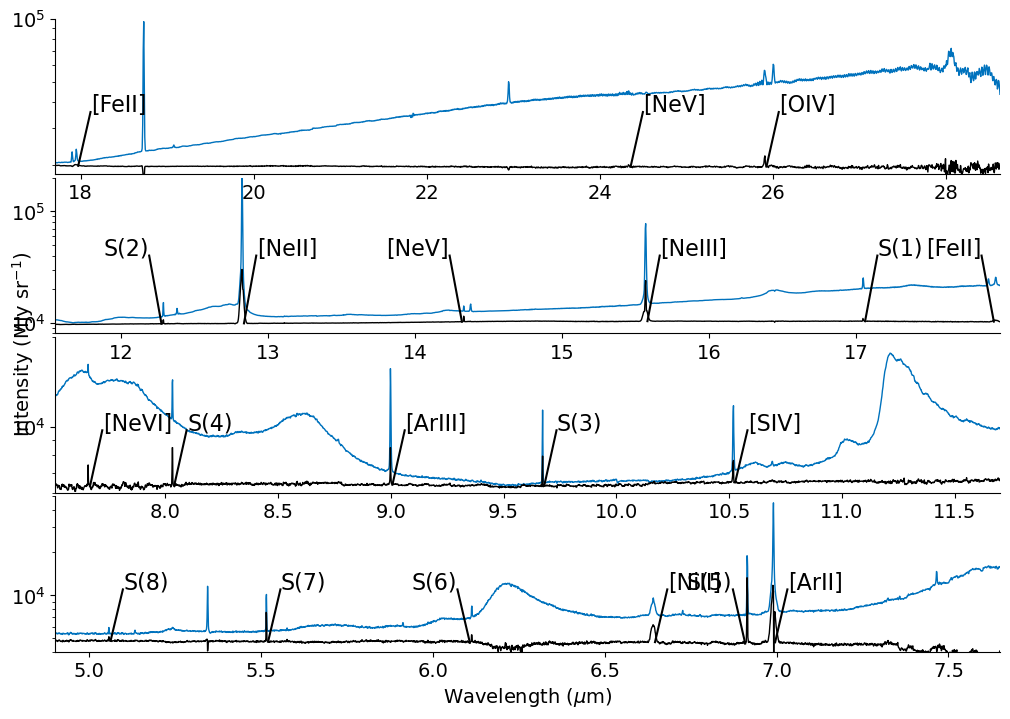

In [9]:
dss3 = diff_spectra(3)
multi_channel_figure(3, dss3)

### Full stitched spectrum of source 3
(Matlab notes this is impractical; kept for completeness.)

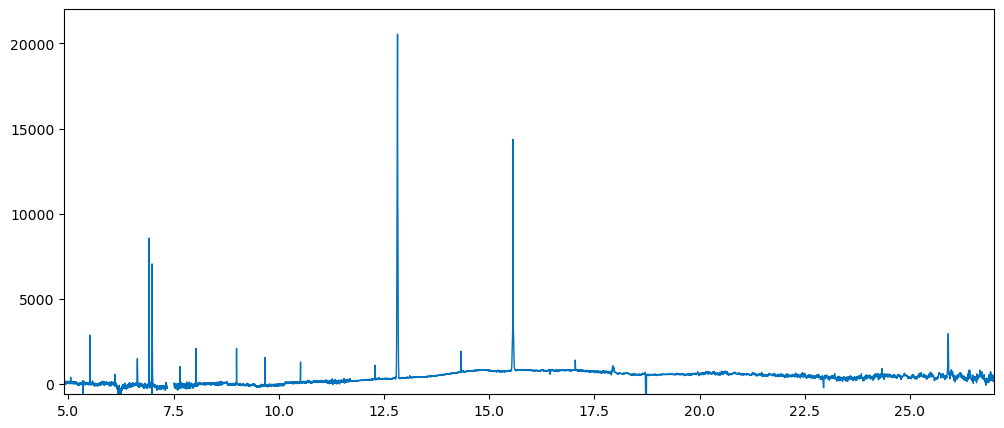

In [10]:
stitched_spectrum(dss3)

## Gaussian fits to broadened lines in source 3
Weighted `gaussfit`; channels contaminated by narrow components get large `ey`.

In [11]:
# (channel, baseline channels (Matlab 1-based ranges), baseline order, last
#  channel of fit region or None, ey overrides (1-based ranges, value),
#  initial K, S, X0, line name)
BROAD_FITS = [
    (1, [(2530, 2590), (2640, 2720)], 5, None, [((82, 90), 1000), ((86, 86), 1e4)],
     6000, 0.2, 6.99, '[ArII]'),
    (1, [(2100, 2150), (2200, 2240)], 3, None, [], 1500, 0.05, 6.64, '[NiII]'),
    (3, [(1540, 1590), (1630, 1680)], 3, None, [((64, 72), 20000)], 3000, 0.05, 15.57, '[NeIII]'),
    (3, [(400, 490), (530, 650)], 3, None, [((106, 114), 30000)], 10000, 0.05, 12.82, '[NeII]'),
    (3, [(2500, 2540)], 1, 2572, [], 300, 0.05, 17.95, '[FeII]'),
]


def broad_line_fits(dss):
    """Gaussian fits (weighted by ey) to broadened lines; prints FWHM in km/s."""
    results = {}
    for ch, bs, order, last, eyset, K, S, X0, name in BROAD_FITS:
        wv, sp = dss[ch][:, 0], dss[ch][:, 1]
        bsix = np.concatenate([np.arange(a - 1, b) for a, b in bs])
        p = np.polyfit(wv[bsix], sp[bsix], order)
        spix = np.arange(bsix.min(), (last if last else bsix.max() + 1))
        wvp = wv[spix]
        spp = sp[spix] - np.polyval(p, wvp)
        noise = np.std(sp[bsix] - np.polyval(p, wv[bsix]), ddof=1)
        ey = np.ones_like(spp) * noise
        for (a, b), v in eyset:
            ey[a - 1:b] = v
        Ko, So, X0o, chi2, ymodel, err, epar = gaussfit(wvp, spp, K, S, X0, 1e-5, 0,
                                                        [1, 1, 1], ey)
        fwhm = So * np.sqrt(np.log(256))
        fwhmv = fwhm / X0o * 3e5
        print(f'FWHM of {name}, {fwhmv:f} km/s')
        results[name] = (Ko, So, X0o, fwhmv, err, epar)
    return results

In [12]:
broad = broad_line_fits(dss3)

FWHM of [ArII], 538.939986 km/s
FWHM of [NiII], 593.511706 km/s
FWHM of [NeIII], 580.735332 km/s
FWHM of [NeII], 563.755997 km/s
FWHM of [FeII], 603.513748 km/s


### Source 1

/janskyraid/bolatto/claude/slice/python_slice_10222026/slice_lib.py:295: RuntimeWarning: divide by zero encountered in divide
  theta = np.arctan(180.0 / (np.pi * np.sqrt(dx**2 + dy**2)))


  1   5.0549 um  263.6368 MJy/sr
  2   5.1302 um  1963.3005 MJy/sr
  3   5.3418 um  15265.6974 MJy/sr
  4   5.5130 um  2106.9452 MJy/sr
  5   5.6112 um  1121.4191 MJy/sr
  6   5.9097 um  2780.0200 MJy/sr
  7   6.1105 um  782.1579 MJy/sr
  8   6.2937 um  922.8807 MJy/sr
  9   6.6375 um  1440.4625 MJy/sr
 10   6.9118 um  5332.8571 MJy/sr
 11   6.9875 um  170872.3877 MJy/sr
 12   7.3545 um  4114.7970 MJy/sr
 13   7.4623 um  19357.7935 MJy/sr
 14   7.5049 um  5818.0765 MJy/sr
 15   7.5104 um  1115.2507 MJy/sr
% num wave(um) peak(MJy/sr) GaussK(MJy/sr) GaussFWHM(um) R(dlam/lam) GaussX(um) Intensity(W/m2/sr) eGaussK eGaussS eGaussX eIntensity flag
  1   5.0549     263.6368     165.4120       0.0025     2001       5.0548 5.22e-08    25.89 0.0004566 0.0001939 1.248e-08  0
  2   5.1302    1963.3005    1222.6763       0.0021     2470       5.1302 3.079e-07    31.93 6.261e-05 2.66e-05 1.228e-08  0
  4   5.5130    2106.9452    1342.3638       0.0017     3172       5.5130 2.45e-07    45.09 6.711e-0

  3   5.3418   15265.6974    9825.4961       0.0020     2739       5.3419 2.143e-06    193.1 4.421e-05 1.882e-05 6.43e-08 32
 11   6.9875  170872.3877  120840.3002       0.0027     2597       6.9875 2.125e-05     1949 5.011e-05 2.128e-05 5.236e-07 32
 13   7.4623   19357.7935   13009.4477       0.0027     2805       7.4623 1.983e-06    336.2 7.937e-05 3.371e-05 7.828e-08 32


  1   5.1302 um  1994.4904 MJy/sr
  2   5.3418 um  14995.9808 MJy/sr
  3   5.5131 um  2098.8028 MJy/sr
  4   5.9098 um  2522.0217 MJy/sr
  5   6.6377 um  1520.1177 MJy/sr
  6   6.9118 um  5293.9054 MJy/sr
  7   6.9875 um  163667.9824 MJy/sr
  8   7.3545 um  3711.2875 MJy/sr
  9   7.4623 um  18921.9165 MJy/sr
 10   7.5049 um  5411.7321 MJy/sr
% num wave(um) peak(MJy/sr) GaussK(MJy/sr) GaussFWHM(um) R(dlam/lam) GaussX(um) Intensity(W/m2/sr) eGaussK eGaussS eGaussX eIntensity flag
  1   5.1302    1994.4904    1260.7809       0.0020     2567       5.1302 3.055e-07    23.82 4.357e-05 1.853e-05 8.814e-09  0
  3   5.5131    2098.8028    1340.1458       0.0018     3081       5.5131 2.518e-07    24.62 3.772e-05 1.623e-05 7.041e-09  0
  4   5.9098    2522.0217    1625.3581       0.0024     2480       5.9098 3.538e-07     24.5 4.147e-05 1.761e-05 8.148e-09  0
  5   6.6377    1520.1177    1038.3630       0.0028     2375       6.6378 2.102e-07    25.01 7.775e-05 3.302e-05 7.735e-09  0
  6   6.9118 

  2   5.3418   14995.9808    9516.8449       0.0021     2551       5.3419 2.228e-06    123.8 3.145e-05 1.336e-05 4.428e-08 32
  7   6.9875  163667.9824  116076.5343       0.0028     2535       6.9875 2.091e-05     1119 3.068e-05 1.303e-05 3.079e-07 32
  9   7.4623   18921.9165   13041.0955       0.0027     2771       7.4622 2.013e-06    268.5 6.404e-05 2.72e-05 6.332e-08 32
 10   7.5049    5411.7321    3706.8002       0.0028     2714       7.5049 5.808e-07    174.8 0.0001506 6.396e-05 4.185e-08 32


...

  1  12.8178 1102366.4219  666457.9052       0.0062     2062      12.8179 8.049e-05     5015 5.408e-05 2.292e-05 9.257e-07 32
  2  15.5608  135962.4641   92953.8526       0.0082     1896      15.5610 1.006e-05    866.3 8.834e-05 3.751e-05 1.432e-07 32
/janskyraid/bolatto/claude/slice/python_slice_10222026/slice_lib.py:295: RuntimeWarning: divide by zero encountered in divide
  theta = np.arctan(180.0 / (np.pi * np.sqrt(dx**2 + dy**2)))


  1   17.8924 um  12729.4738 MJy/sr
  2   17.9420 um  6570.6810 MJy/sr
  3   18.7192 um  419603.9417 MJy/sr
  4   22.9367 um  51448.2814 MJy/sr
  5   24.3364 um  4416.4574 MJy/sr
  6   25.9001 um  25369.5870 MJy/sr
  7   25.9973 um  39937.6060 MJy/sr
% num wave(um) peak(MJy/sr) GaussK(MJy/sr) GaussFWHM(um) R(dlam/lam) GaussX(um) Intensity(W/m2/sr) eGaussK eGaussS eGaussX eIntensity flag
  1  17.8924   12729.4738    7824.2686       0.0111     1609      17.8924 8.673e-07    101.1 0.000175 6.491e-05 1.766e-08  0
  2  17.9420    6570.6810    4220.4250       0.0110     1625      17.9422 4.619e-07    91.57 0.0002669 0.0001243  1.5e-08  0
  3  18.7192  419603.9417  261603.8937       0.0112     1665      18.7191 2.679e-05     1497 7.68e-05 3.019e-05 2.387e-07  0
  4  22.9367   51448.2814   31465.2864       0.0133     1723      22.9366 2.54e-06    450.6 0.0002204 9.337e-05 5.561e-08  0
  5  24.3364    4416.4574    2343.9343       0.0463      526      24.3271 5.846e-07    570.7  0.01301 0.005523

  6  25.9001   25369.5870   15658.8885       0.0126     2050      25.8996 9.411e-07     2161 0.001983 0.0008693 1.967e-07  4
  7  25.9973   39937.6060   21893.3782       0.0108     2415      25.9972 1.113e-06     2382 0.001425 0.0005304 1.907e-07  4
/janskyraid/bolatto/claude/slice/python_slice_10222026/slice_lib.py:1031: RuntimeWarning: invalid value encountered in sqrt
  if np.sqrt(chi2) > 3 * rms:
  3  25.9004   22616.2579   13941.1246       0.0125     2078      25.8999 8.267e-07     2160 0.002203 0.0009605 1.943e-07  4
  4  25.9975   38441.9164   21043.5985       0.0109     2377      25.9974 1.086e-06     2303 0.001463 0.000537 1.878e-07  4
  5  27.8174   15985.2613    5009.7197       0.0139     1996      27.8174 2.879e-07     3058 0.009948 0.004178 2.705e-07 36
  6  27.8456   17009.3361    5015.8583       0.0140     1996      27.8456 2.88e-07     3242  0.01059 0.004406 2.872e-07 36
  7  27.8997   15935.1744    3951.0365       0.0123     2264      27.8996 1.996e-07     2524 0.00930

  1   18.7193 um  413718.3149 MJy/sr
  2   22.9368 um  50374.8439 MJy/sr
  3   25.9002 um  24189.3460 MJy/sr
  4   25.9973 um  39319.3970 MJy/sr
  5   27.8174 um  16188.6922 MJy/sr
  6   27.8456 um  17361.4432 MJy/sr
  7   27.8997 um  16536.8788 MJy/sr
  8   27.9540 um  15430.4106 MJy/sr
  9   28.0621 um  25096.9755 MJy/sr
 10   28.0885 um  17063.1040 MJy/sr
 11   28.1712 um  15809.4877 MJy/sr
 12   28.1986 um  18708.9868 MJy/sr
 13   28.2261 um  17949.8636 MJy/sr
 14   28.2540 um  16921.0775 MJy/sr
 15   28.3084 um  18760.4641 MJy/sr
 16   28.3362 um  18108.5926 MJy/sr
 17   28.3635 um  21439.1295 MJy/sr
 18   28.3913 um  20537.8246 MJy/sr
 19   28.4190 um  22056.2097 MJy/sr
 20   28.4468 um  25924.5699 MJy/sr
 21   28.4753 um  30023.4938 MJy/sr
 22   28.5036 um  23445.4310 MJy/sr
 23   28.5311 um  24298.8396 MJy/sr
 24   28.5591 um  19849.2035 MJy/sr
 25   28.5865 um  21782.9161 MJy/sr
 26   28.6155 um  31964.6310 MJy/sr
% num wave(um) peak(MJy/sr) GaussK(MJy/sr) GaussFWHM(um) R(dlam

  3  25.9002   24189.3460   14921.6464       0.0126     2061      25.8997 8.92e-07     2192 0.002101 0.0009198 1.985e-07  4
  4  25.9973   39319.3970   21487.7940       0.0108     2404      25.9973 1.097e-06     2385 0.001465 0.0005395 1.921e-07  4
  5  27.8174   16188.6922    4803.3861       0.0139     1996      27.8174 2.761e-07     3124   0.0106 0.004451 2.763e-07 36
  6  27.8456   17361.4432    5211.3254       0.0140     1996      27.8456 2.992e-07     3313  0.01042 0.004334 2.935e-07 36
  7  27.8997   16536.8788   19389.0360       0.0040     6941      27.8999 3.195e-07 9.659e+05  0.06486 0.002458 1.673e-05 32
  8  27.9540   15430.4106     978.7133       0.0140     1996      27.9540 5.598e-08     5783  0.09607  0.04039 5.068e-07 36
  9  28.0621   25096.9755   11494.3646       0.0141     1996      28.0621 6.549e-07     4812 0.007037  0.00289 4.274e-07 36
 10  28.0885   17063.1040    6955.0889       0.0141     1996      28.0885 3.959e-07     5290  0.01268 0.005304 4.668e-07 36
 11  2

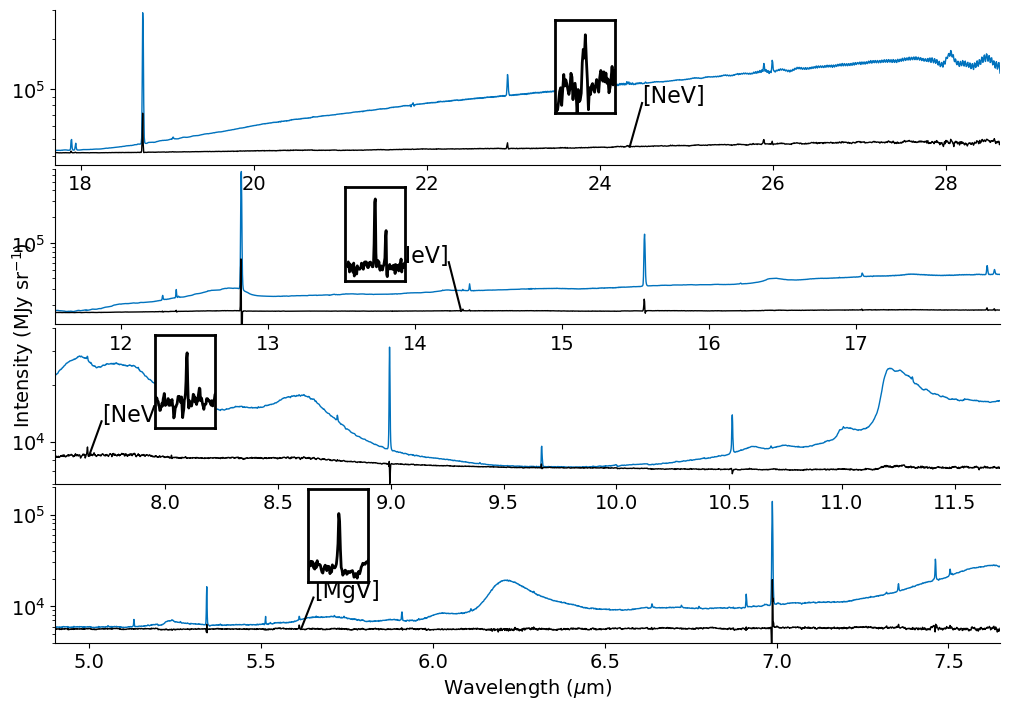

In [13]:
dss1 = diff_spectra(1)
multi_channel_figure(1, dss1)

### Source 2

/janskyraid/bolatto/claude/slice/python_slice_10222026/slice_lib.py:295: RuntimeWarning: divide by zero encountered in divide
  theta = np.arctan(180.0 / (np.pi * np.sqrt(dx**2 + dy**2)))


  1   5.0555 um  180.1892 MJy/sr
  2   5.1311 um  693.9315 MJy/sr
  3   5.3427 um  8961.8313 MJy/sr
  4   5.5141 um  1213.4374 MJy/sr
  5   5.6082 um   85.4159 MJy/sr
  6   5.6126 um  318.0114 MJy/sr
  7   5.9111 um  858.9374 MJy/sr
  8   6.1061 um   86.2829 MJy/sr
  9   6.1115 um  566.1309 MJy/sr
 10   6.2948 um  218.9232 MJy/sr
 11   6.6392 um  836.3378 MJy/sr
 12   6.9131 um  3183.2261 MJy/sr
 13   6.9888 um  67791.6462 MJy/sr
 14   7.3559 um  1093.7059 MJy/sr
 15   7.4636 um  6616.1089 MJy/sr
 16   7.5063 um  1808.9358 MJy/sr
 17   7.5121 um  275.9250 MJy/sr
 18   7.6496 um  370.5394 MJy/sr
% num wave(um) peak(MJy/sr) GaussK(MJy/sr) GaussFWHM(um) R(dlam/lam) GaussX(um) Intensity(W/m2/sr) eGaussK eGaussS eGaussX eIntensity flag
  1   5.0555     180.1892     107.9882       0.0022     2263       5.0555 3.012e-08    14.44 0.0003449 0.0001465 6.152e-09  0
  2   5.1311     693.9315     423.1164       0.0021     2450       5.1310 1.074e-07    27.22 0.0001556 6.609e-05 1.056e-08  0
  3   5

  8   6.1061      86.2829      20.3373       0.0011     5684       6.1094 -1.869e-09    34.86 0.002179 0.001123 4.962e-09  8
 13   6.9888   67791.6462   47017.2562       0.0028     2536       6.9888 8.465e-06    668.3 4.523e-05 1.921e-05 1.838e-07 32
 15   7.4636    6616.1089    4770.4624       0.0029     2555       7.4635 7.982e-07      121 8.551e-05 3.631e-05 3.092e-08 32
 18   7.6496     370.5394 4592636110.0737     622.8173        9    5448.3364  -0.3075 5.894e+94 1.889e+85 1.65e+86 3.947e+84 104


  1   5.3427 um  9209.0190 MJy/sr
  2   5.5141 um  1173.7322 MJy/sr
  3   5.9110 um  797.7680 MJy/sr
  4   6.6391 um  791.6951 MJy/sr
  5   6.9132 um  3078.4570 MJy/sr
  6   6.9888 um  62387.2385 MJy/sr
  7   7.3559 um  1138.0234 MJy/sr
  8   7.4636 um  5983.7311 MJy/sr
  9   7.5063 um  1639.6740 MJy/sr
% num wave(um) peak(MJy/sr) GaussK(MJy/sr) GaussFWHM(um) R(dlam/lam) GaussX(um) Intensity(W/m2/sr) eGaussK eGaussS eGaussX eIntensity flag
  2   5.5141    1173.7322     737.4289       0.0020     2710       5.5141 1.575e-07    11.78 3.751e-05 1.596e-05 3.842e-09  0
  3   5.9110     797.7680     531.3266       0.0026     2286       5.9110 1.255e-07    15.88 8.923e-05 3.789e-05 5.729e-09  0
  4   6.6391     791.6951     595.9962       0.0030     2222       6.6391 1.289e-07    16.97 9.82e-05 4.17e-05 5.606e-09  0
  5   6.9132    3078.4570    2165.4058       0.0027     2548       6.9132 3.922e-07    20.18 2.919e-05 1.24e-05 5.583e-09  0
  7   7.3559    1138.0234     883.1915       0.0031    

  1   5.3427    9209.0190    5963.2467       0.0023     2373       5.3427 1.501e-06    86.35 3.763e-05 1.598e-05 3.319e-08 32
  6   6.9888   62387.2385   44495.2654       0.0029     2438       6.9888 8.334e-06    693.7 5.161e-05 2.192e-05 1.985e-07 32
  8   7.4636    5983.7311    4469.2167       0.0031     2440       7.4635 7.833e-07    97.53 7.709e-05 3.274e-05 2.611e-08 32


...

/janskyraid/bolatto/claude/slice/python_slice_10222026/slice_lib.py:295: RuntimeWarning: divide by zero encountered in divide
  theta = np.arctan(180.0 / (np.pi * np.sqrt(dx**2 + dy**2)))
  5  24.3388     964.6293    1971.8979       0.0044     5505      24.3597 4.692e-08 2.709e+04   0.0241  0.00341 6.934e-07  8
  7  26.0003   23584.3544   13642.6263       0.0135     1923      26.0006 8.708e-07    732.9 0.0008323 0.0003589 7.114e-08  4


  1   17.8951 um  4994.9925 MJy/sr
  2   17.9446 um  3775.0548 MJy/sr
  3   18.7218 um  159430.5052 MJy/sr
  4   22.9402 um  21338.5807 MJy/sr
  5   24.3388 um  964.6293 MJy/sr
  6   25.9027 um  19124.5114 MJy/sr
  7   26.0003 um  23584.3544 MJy/sr
% num wave(um) peak(MJy/sr) GaussK(MJy/sr) GaussFWHM(um) R(dlam/lam) GaussX(um) Intensity(W/m2/sr) eGaussK eGaussS eGaussX eIntensity flag
  1  17.8951    4994.9925    3231.1390       0.0105     1700      17.8951 3.389e-07    35.24 0.0001236 6.305e-05 5.431e-09  0
  2  17.9446    3775.0548    2391.2884       0.0109     1651      17.9445 2.576e-07    36.83 0.000194 8.259e-05 6.073e-09  0
  3  18.7218  159430.5052  101316.0501       0.0110     1709      18.7219 1.01e-05    375.1 4.585e-05 2.069e-05 5.645e-08  0
  4  22.9402   21338.5807   12955.5932       0.0135     1698      22.9404 1.061e-06    137.6 0.0001645 7.081e-05 1.715e-08  0
  6  25.9027   19124.5114   11310.8856       0.0128     2028      25.9028 6.872e-07    922.7 0.001218 0.000504

/janskyraid/bolatto/claude/slice/python_slice_10222026/slice_lib.py:1031: RuntimeWarning: invalid value encountered in sqrt
  if np.sqrt(chi2) > 3 * rms:
  4  26.0000   24948.0794   14253.8516       0.0131     1982      26.0003 8.826e-07    856.5 0.0009018 0.0003903 8.059e-08  4
  5  27.8184    8405.7401    2942.3109       0.0139     1996      27.8184 1.691e-07     1943  0.01072 0.004541 1.714e-07 36
  6  27.8464   10396.0676   41184.0654       0.0256     1087      27.8499 4.342e-06 6.233e+04 0.009706 0.006571 6.775e-06  4
  7  27.8735    8288.0956    3006.4846       0.0140     1996      27.8735 1.725e-07     2864  0.01593 0.006592 2.563e-07 36
  8  27.9007    8825.0043    2101.1382       0.0140     1996      27.9007 1.204e-07     3904  0.03121  0.01274 3.497e-07 36
  9  27.9285    7793.4222    1365.8073       0.0140     1996      27.9285 7.819e-08     5132  0.06333  0.02593 4.599e-07 36
 10  27.9551    7181.4085     243.0036       0.0140     1996      27.9551 1.39e-08     4904   0.335

  1   18.7217 um  160660.4091 MJy/sr
  2   22.9401 um  21674.3062 MJy/sr
  3   25.9026 um  17714.8189 MJy/sr
  4   26.0001 um  24220.2826 MJy/sr
  5   27.8182 um  7618.5493 MJy/sr
  6   27.8463 um  9612.3903 MJy/sr
  7   27.8731 um  8270.9098 MJy/sr
  8   27.9006 um  8480.8510 MJy/sr
  9   27.9284 um  7380.7525 MJy/sr
 10   28.0084 um  7518.4993 MJy/sr
 11   28.0352 um  7972.6388 MJy/sr
 12   28.0623 um  9612.0389 MJy/sr
 13   28.1157 um  9040.8925 MJy/sr
 14   28.1441 um  14068.5465 MJy/sr
 15   28.1755 um  6917.3051 MJy/sr
 16   28.2279 um  7374.1112 MJy/sr
 17   28.2552 um  6864.0070 MJy/sr
 18   28.2823 um  7377.5019 MJy/sr
 19   28.3076 um  10434.5954 MJy/sr
 20   28.3359 um  8748.3010 MJy/sr
 21   28.3630 um  9428.4983 MJy/sr
 22   28.3917 um  10147.2754 MJy/sr
 23   28.4206 um  10842.7797 MJy/sr
 24   28.4475 um  11925.9371 MJy/sr
 25   28.4758 um  13625.8366 MJy/sr
 26   28.5051 um  12549.5254 MJy/sr
 27   28.5314 um  10903.8116 MJy/sr
 28   28.5597 um  11249.5139 MJy/sr
 29   

  4  26.0001   24220.2826   13919.7306       0.0133     1954      26.0004 8.745e-07    788.9 0.0008634 0.0003731 7.533e-08  4
  6  27.8463    9612.3903    3572.4434       0.0079     3529      27.8466 1.16e-07      inf      inf      inf      inf 36
  7  27.8731    8270.9098    2938.4146       0.0140     1996      27.8731 1.686e-07     2391  0.01359 0.005635 2.138e-07 36
  8  27.9006    8480.8510    1861.7361       0.0140     1996      27.9006 1.067e-07     3089   0.0278  0.01136 2.763e-07 36
  9  27.9284    7380.7525    1279.9456       0.0140     1996      27.9284 7.328e-08     3651  0.04679  0.01963 3.221e-07 36
 10  28.0084    7518.4993    3084.5424       0.0140     1996      28.0084 1.761e-07     3437  0.01863 0.007672 3.052e-07 36
 11  28.0352    7972.6388    4568.4019       0.0140     1996      28.0352 2.605e-07     3467  0.01285 0.005292 3.097e-07 36
 12  28.0623    9612.0389    5323.8163       0.0141     1996      28.0623 3.033e-07     3218  0.01009 0.004164 2.846e-07 36
 13  28.

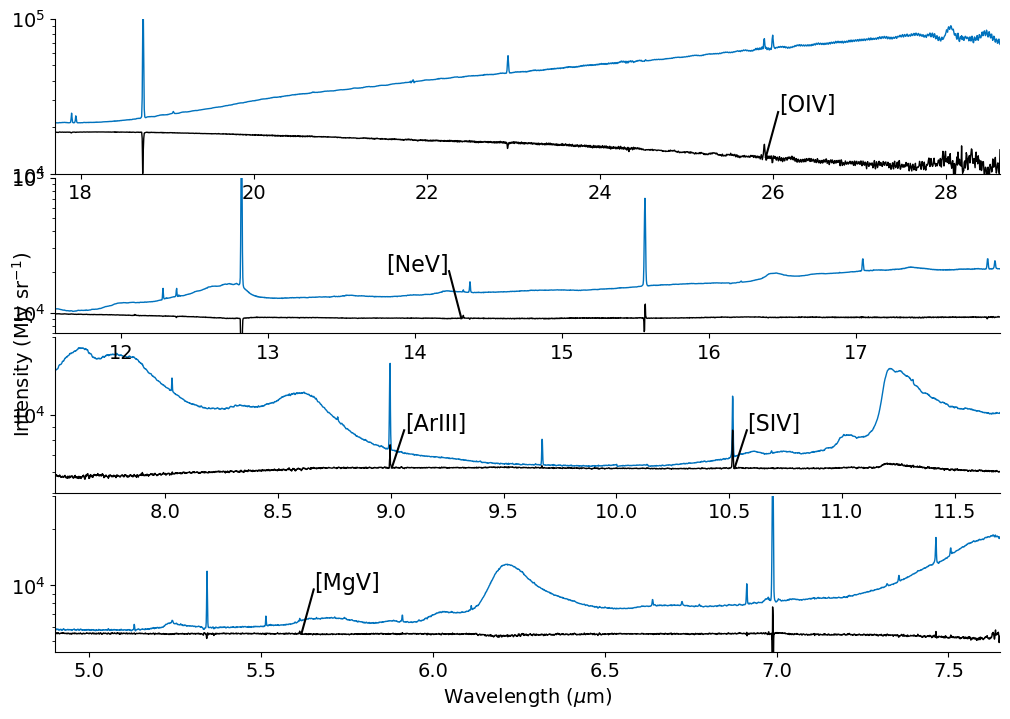

In [14]:
dss2 = diff_spectra(2)
multi_channel_figure(2, dss2)

### Source 4
As in Matlab only ch4 is computed (`for ch=4:4`), so only that panel is drawn.

/janskyraid/bolatto/claude/slice/python_slice_10222026/slice_lib.py:295: RuntimeWarning: divide by zero encountered in divide
  theta = np.arctan(180.0 / (np.pi * np.sqrt(dx**2 + dy**2)))
/janskyraid/bolatto/claude/slice/python_slice_10222026/slice_lib.py:1031: RuntimeWarning: invalid value encountered in sqrt
  if np.sqrt(chi2) > 3 * rms:


  1   17.9020 um  12469.5136 MJy/sr
  2   17.9520 um  6415.2958 MJy/sr
  3   18.7290 um  438196.5051 MJy/sr
  4   19.0784 um  2743.0223 MJy/sr
  5   21.8496 um  5801.2481 MJy/sr
  6   22.9498 um  38667.0610 MJy/sr
  7   24.3387 um  4378.5160 MJy/sr
  8   25.9226 um  7984.6842 MJy/sr
  9   26.0124 um  24777.9959 MJy/sr
% num wave(um) peak(MJy/sr) GaussK(MJy/sr) GaussFWHM(um) R(dlam/lam) GaussX(um) Intensity(W/m2/sr) eGaussK eGaussS eGaussX eIntensity flag
  1  17.9020   12469.5136    7490.7513       0.0114     1568      17.9018 8.517e-07    159.6 0.0002725 0.0001246 2.725e-08  0
  2  17.9520    6415.2958    3597.2396       0.0113     1595      17.9519 4.01e-07    164.2 0.0006269 0.000232 2.887e-08  0
  3  18.7290  438196.5051  278428.3024       0.0113     1653      18.7289 2.87e-05    870.1 3.901e-05 1.849e-05 1.334e-07  0
  4  19.0784    2743.0223    1907.7316       0.0134     1425      19.0778 2.239e-07    150.7 0.001213 0.000522 2.691e-08  0
  5  21.8496    5801.2481    3785.0578    

  4  27.8196   12585.7651    7170.9191       0.0118     2353      27.8198 3.496e-07     2359 0.004392 0.001968 1.735e-07 32
  5  27.8464   11702.9356    7036.9552       0.0119     2338      27.8466 3.45e-07     2673 0.005378 0.002143 2.035e-07 32
  6  27.9004   11267.0917    4509.3926       0.0140     1996      27.9004 2.584e-07     3009  0.01082 0.004554 2.641e-07 36
  7  28.0361   13809.6194    7802.3756       0.0140     1996      28.0361 4.45e-07     2780 0.005997 0.002482 2.474e-07 36
  8  28.0620   14643.0739    7701.5303       0.0141     1996      28.0620 4.388e-07     3188 0.007226 0.002872 2.896e-07 36
  9  28.0885   13358.0065    5222.6881       0.0141     1996      28.0885 2.973e-07     3433  0.01096 0.004584 3.03e-07 36
 10  28.1450   13003.5221    1569.8377       0.0141     1996      28.1450 8.918e-08     4963  0.05159  0.02182 4.312e-07 36
 11  28.1991   12354.4004    4078.0433       0.0141     1996      28.1991 2.312e-07     7213  0.02937  0.01225 6.311e-07 36
 12  28.227

  1   18.7290 um  410004.7043 MJy/sr
  2   22.9499 um  37621.9920 MJy/sr
  3   26.0124 um  24444.6724 MJy/sr
  4   27.8464 um  12750.2486 MJy/sr
  5   28.0358 um  14962.2163 MJy/sr
  6   28.0619 um  16180.1309 MJy/sr
  7   28.0880 um  13769.7448 MJy/sr
  8   28.1451 um  12719.2452 MJy/sr
  9   28.1989 um  13902.0927 MJy/sr
 10   28.2270 um  14447.2783 MJy/sr
 11   28.2549 um  14940.7815 MJy/sr
 12   28.2824 um  15371.4814 MJy/sr
 13   28.3088 um  12763.0744 MJy/sr
 14   28.3369 um  18100.4115 MJy/sr
 15   28.3633 um  14288.3486 MJy/sr
 16   28.3919 um  18515.0410 MJy/sr
 17   28.4203 um  16121.1663 MJy/sr
 18   28.4476 um  17880.1724 MJy/sr
 19   28.4760 um  16389.6956 MJy/sr
 20   28.5035 um  16031.5368 MJy/sr
 21   28.5315 um  15775.0102 MJy/sr
 22   28.5595 um  14303.1514 MJy/sr
 23   28.5881 um  14622.3344 MJy/sr
% num wave(um) peak(MJy/sr) GaussK(MJy/sr) GaussFWHM(um) R(dlam/lam) GaussX(um) Intensity(W/m2/sr) eGaussK eGaussS eGaussX eIntensity flag
  1  18.7290  410004.7043  25937

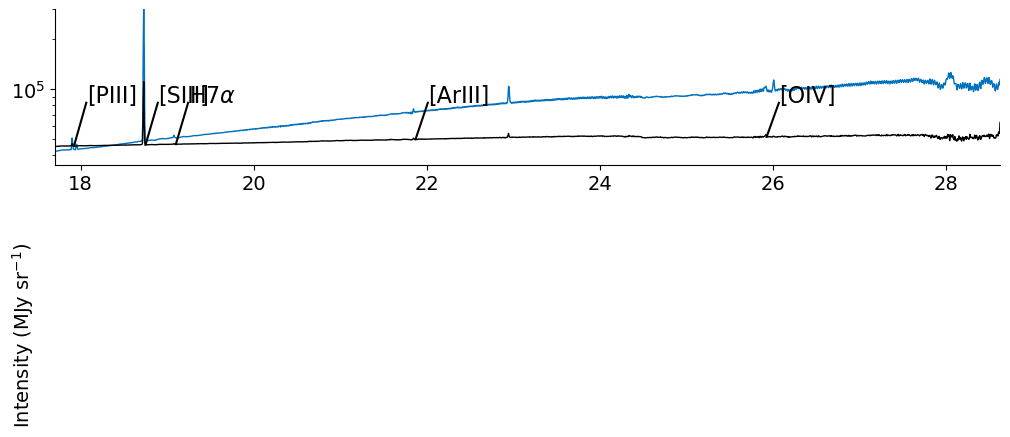

In [15]:
dss4 = diff_spectra(4)
multi_channel_figure(4, dss4)

## ULX X-1 ch4 spectrum
[OIV] brightness, flux and luminosity (no aperture correction).  Saves `ULX-1-spec.png`.

In [16]:
def ulx_spectrum():
    """ch4 spectrum of ULX X-1 and [OIV] brightness/flux/luminosity.  ULX-1-spec.png"""
    cube = read_fits(CUBE.replace('?', '4'), 'xten1')
    q = cat_peaks(cube, _out('ULX-1'), pixco=('09:55:50.102', '69:40:46.9', 0.4),
                  snr=1, linelist=LINELIST4)
    print(f"Brightness of [OIV]: {q['area'][6]:0.2g} +/- {q['earea'][6]:0.2g} W/m2/sr ")
    b2f = np.pi * (R[0, 3] / 3600 * np.pi / 180)**2
    print(f"Flux for [OIV] (no ap corr): {q['area'][6]*b2f:0.2g} +/- "
          f"{q['earea'][6]*b2f:0.2g} W/m2 ")
    f2l = 4 * np.pi * (3.6e6 * 3.09e16)**2 / 3.83e26
    print(f"Luminosity for [OIV] (no ap corr): {q['area'][6]*b2f*f2l:0.2g} +/- "
          f"{q['earea'][6]*b2f*f2l:0.2g} Lsun ")
    cat_peaks(cube, _out('ULX-1-bg'), pixco=('09:55:50.43', '69:40:47.646', 0.4),
              snr=1, linelist=LINELIST4)
    sp = np.loadtxt(_out('ULX-1_spec.txt'), comments='%')

    fig = plt.figure(figsize=(3.6, 3.6))
    ax = fig.add_axes([0.12, 0.14, 0.87, 0.78])
    ax.plot(sp[:, 0], sp[:, 1], 'k', linewidth=2)
    ax.set_xlim(np.min(sp[:, 0]), np.max(sp[:, 0]))
    ax.text(23, 6e4, '[FeIII]', fontsize=16)
    ax.text(18.9, 13e4, '[SIII]', fontsize=16)
    ax.text(19.1, 3e4, r'H7$\alpha$', fontsize=16)
    ax.set_xlabel(r'Wavelength ($\mu$m)', fontsize=16)
    ax.set_ylabel('Intensity (MJy/sr)', fontsize=16)
    ax.set_yscale('log')
    ax.tick_params(labelsize=16, width=2)
    ia = fig.add_axes([0.65, 0.55, 0.25, 0.4])
    ia.plot(sp[:, 0], sp[:, 1], '-k', linewidth=1)
    ia.axis([25.7, 26.2, 4e4, 5.5e4])
    ia.text(25.71, 5e4, '[OIV]', fontsize=15)
    ia.text(26.02, 5.1e4, '[FeII]', fontsize=15)
    ia.set_xticks([])
    ia.set_yticks([])
    fig.savefig(_out('ULX-1-spec.png'), dpi=100, bbox_inches='tight')
    plt.show()
    return q

/janskyraid/bolatto/claude/slice/python_slice_10222026/slice_lib.py:295: RuntimeWarning: divide by zero encountered in divide
  theta = np.arctan(180.0 / (np.pi * np.sqrt(dx**2 + dy**2)))
  8  25.9998   16235.1151    9695.7798       0.0134     1936      26.0000 6.147e-07    478.3 0.0007615 0.0003263 4.62e-08  4


  1   17.8940 um  7449.7525 MJy/sr
  2   17.9444 um  3245.2110 MJy/sr
  3   18.7203 um  226728.3457 MJy/sr
  4   19.0693 um  1328.0121 MJy/sr
  5   21.8402 um  2059.8326 MJy/sr
  6   22.9403 um  28093.3919 MJy/sr
  7   25.9016 um  13472.2249 MJy/sr
  8   25.9998 um  16235.1151 MJy/sr
% num wave(um) peak(MJy/sr) GaussK(MJy/sr) GaussFWHM(um) R(dlam/lam) GaussX(um) Intensity(W/m2/sr) eGaussK eGaussS eGaussX eIntensity flag
  1  17.8940    7449.7525    4690.2859       0.0120     1492      17.8941 5.605e-07    68.13 0.0001976 8.735e-05 1.231e-08  0
  2  17.9444    3245.2110    2097.5805       0.0114     1575      17.9443 2.368e-07    79.43 0.000493 0.0002154 1.362e-08  0
  3  18.7203  226728.3457  137747.2925       0.0120     1555      18.7204 1.51e-05    327.2 3.401e-05 1.351e-05 5.573e-08  0
  4  19.0693    1328.0121     915.6353       0.0125     1523      19.0693 1.006e-07    52.12 0.0008274 0.0003477 8.776e-09  0
  5  21.8402    2059.8326    1085.3980       0.0072     3045      21.8371 

  7  25.9053    5940.3910    3781.3838       0.0216     1198      25.9031 3.89e-07    400.3 0.002644 0.001123 6.29e-08  4
  8  25.9999   11904.5717    7513.8554       0.0146     1779      26.0001 5.183e-07    348.5 0.0007812 0.0003328 3.668e-08  4


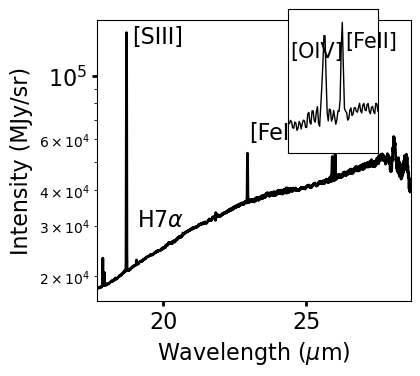

In [17]:
q_ulx = ulx_spectrum()